<a href="https://colab.research.google.com/github/edwinfernandoochoaarenas-maker/Predictive_Analytics_Phase1_Exploration/blob/main/Tarea_2_An%C3%A1lisis_Exploratorio_e_Inferencial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Tarea 2 Análisis Exploratorio e Inferencial**



###Edwin Fernando Ochoa Arenas


Métodos Estadísticos en la Ciencia de Datos y Analítica
203008072_8

Directora de Curso
Lina Rocio Rivadeneira

Universidad Nacional Abierta y a Distancia UNAD
Escuela de Ciencias Básicas, Tecnología e Ingeniería
Especialización en Analítica y Ciencia de Datos
2026



In [ ]:
import pandas as pd
import numpy as np

# 1. Cargar el archivo CSV a un DataFrame

ruta_archivo = "Anexo 1 - Base de Datos dynamic_pricing.csv"
df = pd.read_csv(ruta_archivo)

# 2. Visualización inicial del DataFrame
print("Dimensiones (filas, columnas):", df.shape)
print("\nPrimeras 5 filas:")
display(df.head())

print("\nInformación general y tipos de datos:")
df.info()

print("\nResumen estadístico de variables numéricas:")
display(df.describe().T)

Dimensiones (filas, columnas): (1000, 10)

Primeras 5 filas:


,Number_of_Riders,Number_of_Drivers,Location_Category,Customer_Loyalty_Status,Number_of_Past_Rides,Average_Ratings,Time_of_Booking,Vehicle_Type,Expected_Ride_Duration,Historical_Cost_of_Ride
0,90,45,Urban,Silver,13,4.47,Night,Premium,90,284.257273
1,58,39,Suburban,Silver,72,4.06,Evening,Economy,43,173.874753
2,42,31,Rural,Silver,0,3.99,Afternoon,Premium,76,329.795469
3,89,28,Rural,Regular,67,4.31,Afternoon,Premium,134,470.201232
4,78,22,Rural,Regular,74,3.77,Afternoon,Economy,149,579.681422



Información general y tipos de datos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Number_of_Riders         1000 non-null   int64  
 1   Number_of_Drivers        1000 non-null   int64  
 2   Location_Category        1000 non-null   object 
 3   Customer_Loyalty_Status  1000 non-null   object 
 4   Number_of_Past_Rides     1000 non-null   int64  
 5   Average_Ratings          1000 non-null   float64
 6   Time_of_Booking          1000 non-null   object 
 7   Vehicle_Type             1000 non-null   object 
 8   Expected_Ride_Duration   1000 non-null   int64  
 9   Historical_Cost_of_Ride  1000 non-null   float64
dtypes: float64(2), int64(4), object(4)
memory usage: 78.3+ KB

Resumen estadístico de variables numéricas:


,count,mean,std,min,25%,50%,75%,max
Number_of_Riders,1000.0,60.372000,23.701506,20.000000,40.000000,60.000000,81.000000,100.000000
Number_of_Drivers,1000.0,27.076000,19.068346,5.000000,11.000000,22.000000,38.000000,89.000000
Number_of_Past_Rides,1000.0,50.031000,29.313774,0.000000,25.000000,51.000000,75.000000,100.000000
Average_Ratings,1000.0,4.257220,0.435781,3.500000,3.870000,4.270000,4.632500,5.000000
Expected_Ride_Duration,1000.0,99.588000,49.165450,10.000000,59.750000,102.000000,143.000000,180.000000
Historical_Cost_of_Ride,1000.0,372.502623,187.158756,25.993449,221.365202,362.019426,510.497504,836.116419


In [ ]:
# 3. Higiene básica de los datos
# 3.1 Revisar valores nulos
print("\nValores nulos por columna:")
print(df.isnull().sum())

# 3.2 Revisar y eliminar filas completamente duplicadas
duplicados = df.duplicated().sum()
print(f"\nFilas duplicadas encontradas: {duplicados}")
if duplicados > 0:
    df = df.drop_duplicates().reset_index(drop=True)

# 3.3 Limpiar espacios en blanco extra en columnas de texto
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# 3.4 Verificar categorías únicas en variables categóricas clave
categoricas = ["Location_Category", "Customer_Loyalty_Status", "Time_of_Booking", "Vehicle_Type"]
for col in categoricas:
    if col in df.columns:
        print(f"\nCategorías en '{col}': {df[col].unique()}")
        print(df[col].value_counts(dropna=False))

# 3.5 Verificar que las variables numéricas clave no tengan valores negativos imposibles
# (por ejemplo, duración, costo o calificación)
for col in ["Expected_Ride_Duration", "Historical_Cost_of_Ride", "Average_Ratings"]:
    if col in df.columns:
        negativos = (df[col] < 0).sum()
        print(f"\nValores negativos en '{col}': {negativos}")


Valores nulos por columna:
Number_of_Riders           0
Number_of_Drivers          0
Location_Category          0
Customer_Loyalty_Status    0
Number_of_Past_Rides       0
Average_Ratings            0
Time_of_Booking            0
Vehicle_Type               0
Expected_Ride_Duration     0
Historical_Cost_of_Ride    0
dtype: int64

Filas duplicadas encontradas: 0

Categorías en 'Location_Category': ['Urban' 'Suburban' 'Rural']
Location_Category
Urban       346
Rural       332
Suburban    322
Name: count, dtype: int64

Categorías en 'Customer_Loyalty_Status': ['Silver' 'Regular' 'Gold']
Customer_Loyalty_Status
Silver     367
Regular    320
Gold       313
Name: count, dtype: int64

Categorías en 'Time_of_Booking': ['Night' 'Evening' 'Afternoon' 'Morning']
Time_of_Booking
Night        276
Afternoon    247
Morning      246
Evening      231
Name: count, dtype: int64

Categorías en 'Vehicle_Type': ['Premium' 'Economy']
Vehicle_Type
Premium    522
Economy    478
Name: count, dtype: int64

Valor

In [ ]:
import numpy as np

# Extraemos la columna 'Expected_Ride_Duration' del DataFrame ya validado
# (1,000 registros sin valores nulos, negativos ni duplicados).
variable = df["Expected_Ride_Duration"]

# Definimos el tamaño de cada muestra aleatoria (n = 40 observaciones por muestra)
# y la cantidad total de veces que repetiremos el muestreo (2,500 muestras).
n = 40
repeticiones = 2500

# Inicializamos el generador de números aleatorios con una semilla fija (42)
# para que la extracción de muestras sea reproducible en futuras ejecuciones.
rng = np.random.default_rng(42)

# Generamos 2,500 muestras de tamaño 40 seleccionando valores al azar con reemplazo
# desde el arreglo de la variable; el resultado es una matriz de forma (2500, 40).
muestras = rng.choice(variable.to_numpy(), size=(repeticiones, n), replace=True)

# Calculamos el promedio de cada una de las 2,500 muestras (promediando a lo largo
# del eje 1, es decir, across las 40 observaciones de cada fila).
medias_muestrales = muestras.mean(axis=1)

# Verificamos rápidamente la longitud del vector resultante y los primeros 5 promedios.
print("Total de medias muestrales calculadas:", len(medias_muestrales))
print("Primeras 5 medias muestrales:", np.round(medias_muestrales[:5], 2))

Total de medias muestrales calculadas: 2500
Primeras 5 medias muestrales: [ 91.7  104.02  95.32 104.62  90.08]


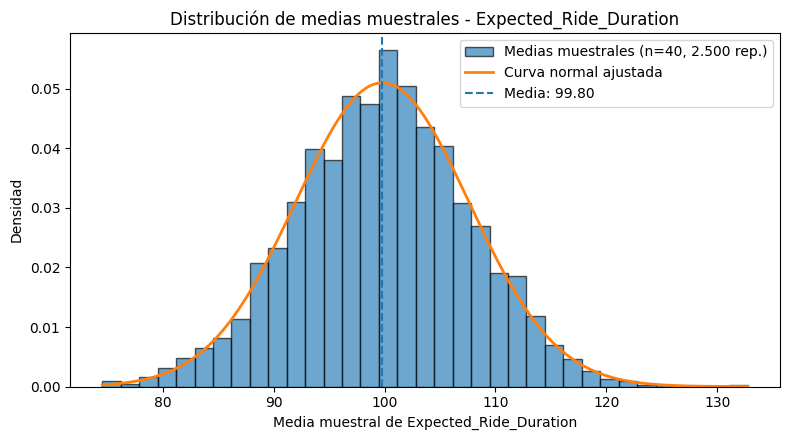

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm

media_muestral = medias_muestrales.mean()
std_muestral = medias_muestrales.std(ddof=1)

fig, ax = plt.subplots(figsize=(8, 4.5))

# Histograma normalizado de las 2,500 medias muestrales
ax.hist(
    medias_muestrales,
    bins=35,
    density=True,
    alpha=0.65,
    edgecolor="black",
    label="Medias muestrales (n=40, 2.500 rep.)"
)

# Curva normal teórica ajustada con media y desviación estándar empíricas
x_vals = np.linspace(medias_muestrales.min(), medias_muestrales.max(), 200)
ax.plot(x_vals, norm.pdf(x_vals, media_muestral, std_muestral), linewidth=2, label="Curva normal ajustada")

# Línea vertical en la media de las medias muestrales
ax.axvline(media_muestral, linestyle="--", linewidth=1.5, label=f"Media: {media_muestral:.2f}")

ax.set_title("Distribución de medias muestrales - Expected_Ride_Duration")
ax.set_xlabel("Media muestral de Expected_Ride_Duration")
ax.set_ylabel("Densidad")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
from scipy import stats

# Extraer la variable sin valores nulos
duracion = df['Expected_Ride_Duration'].dropna()

# Estadísticos muestrales
n = len(duracion)
media = duracion.mean()
desv_est = duracion.std(ddof=1)
error_estandar = desv_est / np.sqrt(n)

# Intervalo de confianza del 95% con distribución t de Student
confianza = 0.95
gl = n - 1
ic_media = stats.t.interval(confianza, df=gl, loc=media, scale=error_estandar)

print(f"n = {n}")
print(f"Media muestral = {media:.4f}")
print(f"Desviación estándar = {desv_est:.4f}")
print(f"Error estándar = {error_estandar:.4f}")
print(f"IC 95% para la media = ({ic_media[0]:.4f}, {ic_media[1]:.4f})")

n = 1000
Media muestral = 99.5880
Desviación estándar = 49.1655
Error estándar = 1.5547
IC 95% para la media = (96.5371, 102.6389)


In [ ]:
import numpy as np
from scipy import stats

# Extraer variable sin nulos y definir condición de éxito (>= 4.0)
ratings = df['Average_Ratings'].dropna()
n = len(ratings)
exitos = (ratings >= 4.0).sum()
p_hat = exitos / n

# Nivel de confianza del 95%
confianza = 0.95
alpha = 1 - confianza
z_crit = stats.norm.ppf(1 - alpha / 2)

# 1. Intervalo clásico (Wald / aproximación normal)
ee_prop = np.sqrt(p_hat * (1 - p_hat) / n)
ic_wald = (p_hat - z_crit * ee_prop, p_hat + z_crit * ee_prop)

# 2. Intervalo de Wilson (más preciso si p_hat es muy cercana a 0 o 1)
denom = 1 + (z_crit**2) / n
centro = (p_hat + (z_crit**2) / (2 * n)) / denom
margen = (z_crit * np.sqrt((p_hat * (1 - p_hat) + (z_crit**2) / (4 * n)) / n)) / denom
ic_wilson = (centro - margen, centro + margen)

print(f"n = {n}")
print(f"Éxitos (ratings >= 4.0) = {exitos}")
print(f"Proporción muestral (p_hat) = {p_hat:.4f} ({p_hat*100:.2f}%)")
print(f"Error estándar = {ee_prop:.4f}")
print(f"IC 95% Wald = ({ic_wald[0]:.4f}, {ic_wald[1]:.4f})")
print(f"IC 95% Wilson = ({ic_wilson[0]:.4f}, {ic_wilson[1]:.4f})")

n = 1000
Éxitos (ratings >= 4.0) = 686
Proporción muestral (p_hat) = 0.6860 (68.60%)
Error estándar = 0.0147
IC 95% Wald = (0.6572, 0.7148)
IC 95% Wilson = (0.6566, 0.7140)


In [ ]:
import numpy as np
from scipy import stats

# 1. Extraer variable sin nulos
costo = df['Historical_Cost_of_Ride'].dropna()
n = len(costo)
media = costo.mean()
varianza = costo.var(ddof=1)
desv_est = costo.std(ddof=1)

# 2. Prueba de normalidad de Shapiro-Wilk
stat_sw, p_sw = stats.shapiro(costo)

# 3. IC del 95% clásico basado en Chi-cuadrado
confianza = 0.95
alpha = 1 - confianza
gl = n - 1
chi2_inf = stats.chi2.ppf(1 - alpha / 2, df=gl)
chi2_sup = stats.chi2.ppf(alpha / 2, df=gl)
ic_chi2 = (gl * varianza / chi2_inf, gl * varianza / chi2_sup)

# 4. IC del 95% complementario por Bootstrap (percentiles)
rng = np.random.default_rng(42)
n_boot = 5000
boot_vars = np.array([
    rng.choice(costo.to_numpy(), size=n, replace=True).var(ddof=1)
    for _ in range(n_boot)
])
ic_boot = np.percentile(boot_vars, [2.5, 97.5])

print(f"n = {n}")
print(f"Media muestral = {media:.4f}")
print(f"Varianza muestral (s^2) = {varianza:.4f}")
print(f"Desviación estándar (s) = {desv_est:.4f}")
print(f"Shapiro-Wilk: W = {stat_sw:.4f}, p = {p_sw:.4e}")
print(f"IC 95% Chi-cuadrado = ({ic_chi2[0]:.4f}, {ic_chi2[1]:.4f})")
print(f"IC 95% Bootstrap    = ({ic_boot[0]:.4f}, {ic_boot[1]:.4f})")

n = 1000
Media muestral = 372.5026
Varianza muestral (s^2) = 35028.4000
Desviación estándar (s) = 187.1588
Shapiro-Wilk: W = 0.9799, p = 1.5951e-10
IC 95% Chi-cuadrado = (32148.6333, 38315.2670)
IC 95% Bootstrap    = (32588.2831, 37450.1662)


In [ ]:
df['Customer_Loyalty_Status'].value_counts()


,count
Customer_Loyalty_Status,
Silver,367
Regular,320
Gold,313


In [ ]:
from scipy import stats

# Filtrar datos sin nulos para Silver vs. Regular
df_medias = df[['Customer_Loyalty_Status', 'Expected_Ride_Duration']].dropna()
silver = df_medias[df_medias['Customer_Loyalty_Status'] == 'Silver']['Expected_Ride_Duration']
regular = df_medias[df_medias['Customer_Loyalty_Status'] == 'Regular']['Expected_Ride_Duration']

# Verificación de supuestos
sw_silver = stats.shapiro(silver)
sw_regular = stats.shapiro(regular)
levene_res = stats.levene(silver, regular)

# Prueba t para muestras independientes (Student y Welch)
t_student = stats.ttest_ind(silver, regular, equal_var=True)
t_welch = stats.ttest_ind(silver, regular, equal_var=False)

print("=== PRUEBA T PARA MEDIAS: Expected_Ride_Duration (Silver vs. Regular) ===")
print(f"Silver:  n = {len(silver)}, media = {silver.mean():.4f}, desv = {silver.std(ddof=1):.4f}, Shapiro p = {sw_silver.pvalue:.4e}")
print(f"Regular: n = {len(regular)}, media = {regular.mean():.4f}, desv = {regular.std(ddof=1):.4f}, Shapiro p = {sw_regular.pvalue:.4e}")
print(f"Levene:  stat = {levene_res.statistic:.4f}, p = {levene_res.pvalue:.4f}")
print(f"t Student (equal_var=True):  t = {t_student.statistic:.4f}, p = {t_student.pvalue:.4f}")
print(f"t Welch   (equal_var=False): t = {t_welch.statistic:.4f}, p = {t_welch.pvalue:.4f}")

=== PRUEBA T PARA MEDIAS: Expected_Ride_Duration (Silver vs. Regular) ===
Silver:  n = 367, media = 97.0163, desv = 48.1588, Shapiro p = 3.2036e-08
Regular: n = 320, media = 100.5656, desv = 49.3442, Shapiro p = 1.0062e-08
Levene:  stat = 0.8728, p = 0.3505
t Student (equal_var=True):  t = -0.9526, p = 0.3411
t Welch   (equal_var=False): t = -0.9510, p = 0.3419


In [ ]:
import numpy as np
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest

# Filtrar datos sin nulos para Economy vs. Premium
df_prop = df[['Vehicle_Type', 'Average_Ratings']].dropna().copy()
df_prop['rating_alto'] = (df_prop['Average_Ratings'] >= 4.0).astype(int)

eco = df_prop[df_prop['Vehicle_Type'] == 'Economy']['rating_alto']
prem = df_prop[df_prop['Vehicle_Type'] == 'Premium']['rating_alto']

# Conteos y proporciones
x_eco, n_eco = eco.sum(), len(eco)
x_prem, n_prem = prem.sum(), len(prem)
p_eco = x_eco / n_eco
p_prem = x_prem / n_prem

# Verificación de supuesto de normalidad asintótica (n*p >= 5 y n*(1-p) >= 5)
sup_eco = (n_eco * p_eco >= 5) and (n_eco * (1 - p_eco) >= 5)
sup_prem = (n_prem * p_prem >= 5) and (n_prem * (1 - p_prem) >= 5)

# Prueba t sobre variable binaria (0/1) - aproximación t para diferencia de proporciones
levene_prop = stats.levene(eco, prem)
t_prop_student = stats.ttest_ind(eco, prem, equal_var=True)
t_prop_welch = stats.ttest_ind(eco, prem, equal_var=False)

# Prueba z de dos proporciones (estándar asintótico de referencia)
z_stat, z_pval = proportions_ztest([x_eco, x_prem], [n_eco, n_prem], alternative='two-sided')

print("=== PRUEBA PARA DIFERENCIA DE PROPORCIONES: Average_Ratings >= 4.0 (Economy vs. Premium) ===")
print(f"Economy: x = {x_eco}, n = {n_eco}, p = {p_eco:.4f} ({p_eco*100:.2f}%) | np>=5 y n(1-p)>=5: {sup_eco}")
print(f"Premium: x = {x_prem}, n = {n_prem}, p = {p_prem:.4f} ({p_prem*100:.2f}%) | np>=5 y n(1-p)>=5: {sup_prem}")
print(f"Levene (binaria): stat = {levene_prop.statistic:.4f}, p = {levene_prop.pvalue:.4f}")
print(f"t Student (binaria, equal_var=True):  t = {t_prop_student.statistic:.4f}, p = {t_prop_student.pvalue:.4f}")
print(f"t Welch   (binaria, equal_var=False): t = {t_prop_welch.statistic:.4f}, p = {t_prop_welch.pvalue:.4f}")
print(f"z Proporciones (referencia):          z = {z_stat:.4f}, p = {z_pval:.4f}")

=== PRUEBA PARA DIFERENCIA DE PROPORCIONES: Average_Ratings >= 4.0 (Economy vs. Premium) ===
Economy: x = 333, n = 478, p = 0.6967 (69.67%) | np>=5 y n(1-p)>=5: True
Premium: x = 353, n = 522, p = 0.6762 (67.62%) | np>=5 y n(1-p)>=5: True
Levene (binaria): stat = 0.4817, p = 0.4878
t Student (binaria, equal_var=True):  t = 0.6940, p = 0.4878
t Welch   (binaria, equal_var=False): t = 0.6946, p = 0.4875
z Proporciones (referencia):          z = 0.6946, p = 0.4873


In [ ]:
import numpy as np
from scipy import stats

# Grupos de Customer_Loyalty_Status a comparar
grupo_1_nombre = 'Silver'
grupo_2_nombre = 'Regular'

# Filtrar datos sin nulos
df_var = df[['Customer_Loyalty_Status', 'Expected_Ride_Duration']].dropna()
g1 = df_var[df_var['Customer_Loyalty_Status'] == grupo_1_nombre]['Expected_Ride_Duration']
g2 = df_var[df_var['Customer_Loyalty_Status'] == grupo_2_nombre]['Expected_Ride_Duration']

# Estadísticos descriptivos y varianzas muestrales (ddof=1)
n1, n2 = len(g1), len(g2)
var1, var2 = g1.var(ddof=1), g2.var(ddof=1)
std1, std2 = g1.std(ddof=1), g2.std(ddof=1)

# Verificación de normalidad (Shapiro-Wilk por grupo)
sw1 = stats.shapiro(g1)
sw2 = stats.shapiro(g2)

# Prueba F de Fisher bilateral (F = s1^2 / s2^2)
f_stat = var1 / var2
df1, df2 = n1 - 1, n2 - 1
p_val_f = 2 * min(stats.f.cdf(f_stat, df1, df2), 1 - stats.f.cdf(f_stat, df1, df2))

# Prueba de Levene (referencia robusta ante desviaciones de normalidad)
levene_res = stats.levene(g1, g2)

print(f"=== SECCIÓN 2.4: PRUEBA F DE FISHER ({grupo_1_nombre} vs. {grupo_2_nombre}) ===")
print(f"{grupo_1_nombre}: n = {n1}, varianza = {var1:.4f}, desv = {std1:.4f}, Shapiro p = {sw1.pvalue:.4e}")
print(f"{grupo_2_nombre}: n = {n2}, varianza = {var2:.4f}, desv = {std2:.4f}, Shapiro p = {sw2.pvalue:.4e}")
print(f"F de Fisher: F = {f_stat:.4f}, gl = ({df1}, {df2}), p = {p_val_f:.4f}")
print(f"Levene (referencia): stat = {levene_res.statistic:.4f}, p = {levene_res.pvalue:.4f}")

=== SECCIÓN 2.4: PRUEBA F DE FISHER (Silver vs. Regular) ===
Silver: n = 367, varianza = 2319.2730, desv = 48.1588, Shapiro p = 3.2036e-08
Regular: n = 320, varianza = 2434.8546, desv = 49.3442, Shapiro p = 1.0062e-08
F de Fisher: F = 0.9525, gl = (366, 319), p = 0.6517
Levene (referencia): stat = 0.8728, p = 0.3505


In [ ]:
import pandas as pd

# Filtrar filas sin valores nulos en ambas variables
df_tc = df[['Customer_Loyalty_Status', 'Vehicle_Type']].dropna()

# Tabla de contingencia (frecuencias observadas con totales marginales)
tabla_contingencia = pd.crosstab(
    df_tc['Customer_Loyalty_Status'],
    df_tc['Vehicle_Type'],
    margins=True,
    margins_name='Total'
)

print(tabla_contingencia)

Vehicle_Type             Economy  Premium  Total
Customer_Loyalty_Status                         
Gold                         153      160    313
Regular                      144      176    320
Silver                       181      186    367
Total                        478      522   1000


In [ ]:
import numpy as np
from scipy import stats

# Frecuencias observadas en el orden de filas (Gold, Regular, Silver) y columnas (Economy, Premium)
observados = np.array([
    [153, 160],  # Gold
    [144, 176],  # Regular
    [181, 186]   # Silver
])

chi2_stat, p_val, dof, esperados = stats.chi2_contingency(observados)

print(f"Chi-cuadrado (chi2) = {chi2_stat:.4f}")
print(f"Grados de libertad (gl) = {dof}")
print(f"Valor p = {p_val:.4f}")
print(f"Frecuencia esperada mínima = {esperados.min():.2f}")
print("\nFrecuencias esperadas:")
print(np.round(esperados, 2))

Chi-cuadrado (chi2) = 1.4916
Grados de libertad (gl) = 2
Valor p = 0.4744
Frecuencia esperada mínima = 149.61

Frecuencias esperadas:
[[149.61 163.39]
 [152.96 167.04]
 [175.43 191.57]]


In [17]:
import numpy as np
from scipy import stats
from statsmodels.stats.power import TTestIndPower

# Datos de la prueba t: Expected_Ride_Duration (Silver vs. Regular)
n_silver, mean_silver, std_silver = 367, 97.0163, 48.1588
n_regular, mean_regular, std_regular = 320, 100.5656, 49.3442
alpha = 0.05

# Tamaño del efecto estimado (d de Cohen con desviación estándar combinada)
df_total = n_silver + n_regular - 2
s_pooled = np.sqrt(
    ((n_silver - 1) * std_silver**2 + (n_regular - 1) * std_regular**2) / df_total
)
d_cohen = abs(mean_silver - mean_regular) / s_pooled

# Poder estadístico estimado (prueba bilateral)
power_calc = TTestIndPower()
poder = power_calc.solve_power(
    effect_size=d_cohen,
    nobs1=n_silver,
    alpha=alpha,
    ratio=n_regular / n_silver,
    alternative='two-sided'
)

print(f"Tamaño de muestra: n_Silver = {n_silver}, n_Regular = {n_regular} (Total N = {n_silver + n_regular})")
print(f"Nivel de significancia (alpha): {alpha}")
print(f"Tamaño del efecto estimado (d de Cohen): {d_cohen:.4f}")
print(f"Poder estadístico estimado (1 - beta): {poder:.4f} ({poder*100:.2f}%)")

Tamaño de muestra: n_Silver = 367, n_Regular = 320 (Total N = 687)
Nivel de significancia (alpha): 0.05
Tamaño del efecto estimado (d de Cohen): 0.0729
Poder estadístico estimado (1 - beta): 0.1584 (15.84%)
